# 09 · Every model, retrained on Claude's labels
Notebooks 04–07 trained on the embedding-similarity labels from notebook 02. This notebook reruns all of them with `y` = Claude's label (`data/labeled_answers_claude.jsonl`, from `src/llm_judge.py`), on the same hidden states and the same train/val/test split:

| Part | Reruns | On Claude's labels |
|---|---|---|
| A | 04 · baseline probe | layer 16, last token, logistic regression, C picked on val |
| B | 05 · layer sweep | one probe per layer, val-selected and cross-validated |
| C | 06 · improvement ablation | same candidates; the "clear-cut labels" filter becomes "Claude's high-confidence labels" |
| D | 07 · model comparison | all 11 model types, plus the new DualPositionNet from notebook 08 |

Steps 01–03 don't depend on the labels, so they aren't rerun. Earlier notebooks and their results are unchanged.

**Reported for every model:** CV AUROC and accuracy (grouped 5-fold on train+val, repeated 3 times); val accuracy and AUROC (fit on train, score val); test accuracy, balanced accuracy and AUROC (fit on train+val, score test). Accuracy uses p > 0.5. Settings are picked by CV AUROC, never by val or test. Part A keeps notebook 04's own recipe, so its C is picked on val.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%load_ext autoreload
%autoreload 2
from src import config

In [2]:
import time, json, warnings, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.io_utils import read_jsonl
from src.improve import load_probe_data, layer_average
from src.relabel import with_claude_labels, evaluate_everywhere
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

d0 = load_probe_data(read_jsonl(config.ALL_LAYERS_DATASET_PATH))
d, conf, old_y = with_claude_labels(d0)
HIGH = 2                       # Claude confidence rank: 0 low, 1 medium, 2 high
LATE = list(range(18, 37))
tag = f"{config.MODEL_NAME.split('/')[-1]}_claude_labels"
summary_rows = []              # one row per final model, across parts A-D

def record(part, name, model):
    t = time.time()
    r = evaluate_everywhere(d, model)
    r.pop('test_probs')
    summary_rows.append({'part': part, 'model': name, **r, 'seconds': round(time.time() - t, 1)})
    return r

print(f"{len(d.y)} answers; Claude hallucination rate {d.y.mean():.3f}; agreement with old labels {(old_y == d.y).mean():.3f}")
print({s: int((d.split == s).sum()) for s in ('train', 'val', 'test')})
print(f"majority-class accuracy: val {max(d.y[d.split == 'val'].mean(), 1 - d.y[d.split == 'val'].mean()):.3f}, "
      f"test {max(d.y[d.test].mean(), 1 - d.y[d.test].mean()):.3f}")

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


500 answers; Claude hallucination rate 0.420; agreement with old labels 0.716
{'train': 350, 'val': 75, 'test': 75}
majority-class accuracy: val 0.613, test 0.613


## A · Baseline probe (notebook 04 recipe)

In [3]:
from src.probe import train_probe
from src.improve import linear_probe
splits16 = {s: (d.answer_last[d.split == s, config.LAYER_INDEX], d.y[d.split == s]) for s in ('train', 'val', 'test')}
probe16, C16, m16 = train_probe(splits16, verbose=True)
config.MODELS_DIR.mkdir(exist_ok=True); config.RESULTS_DIR.mkdir(exist_ok=True)
joblib.dump(probe16, config.MODELS_DIR / f"probe_{config.MODEL_NAME.split('/')[-1]}_L{config.LAYER_INDEX}_{config.TOKEN_POSITION_METHOD}_claude.joblib")
(config.RESULTS_DIR / f'metrics_{tag}_L{config.LAYER_INDEX}.json').write_text(json.dumps({'C': C16, **m16}, indent=2))
record('A', 'Baseline: LR layer 16 (C picked on val)', linear_probe(d, lambda i: d.answer_last[i, config.LAYER_INDEX], C16))
pd.DataFrame(m16).T.round(3)

C=1e-05: val AUROC=0.779
C=0.0001: val AUROC=0.799
C=0.001: val AUROC=0.823
C=0.01: val AUROC=0.815
C=0.1: val AUROC=0.798
C=1.0: val AUROC=0.786


,auroc,accuracy,f1
train,0.893,0.820,0.795
val,0.823,0.787,0.742
test,0.715,0.707,0.621


## B · Layer sweep

In [4]:
from src.probe import layer_sweep
all_splits = {s: (d.answer_last[d.split == s], d.y[d.split == s]) for s in ('train', 'val', 'test')}
cv_groups = [q for s in ('train', 'val') for q in d.question_id[d.split == s]]
sweep, _ = layer_sweep(all_splits, cv_groups=cv_groups)
sweep.to_csv(config.RESULTS_DIR / f'layer_sweep_{tag}.csv', index=False)
best_cv_layer = int(sweep.loc[sweep['cv_auroc'].idxmax(), 'layer_index'])
print(f"best layer by CV AUROC: {best_cv_layer} ({sweep['cv_auroc'].max():.3f}); layer 16: {sweep.loc[16, 'cv_auroc']:.3f}")
sweep[['layer_index', 'C', 'val_accuracy', 'val_auroc', 'test_accuracy', 'test_auroc', 'cv_auroc']].round(3).T

Layer sweep:   0%|          | 0/37 [00:00<?, ?it/s]

Layer sweep:   3%|▎         | 1/37 [00:00<00:25,  1.43it/s]

Layer sweep:   5%|▌         | 2/37 [00:01<00:26,  1.30it/s]

Layer sweep:   8%|▊         | 3/37 [00:02<00:26,  1.27it/s]

Layer sweep:  11%|█         | 4/37 [00:03<00:25,  1.28it/s]

Layer sweep:  14%|█▎        | 5/37 [00:03<00:25,  1.28it/s]

... (31 outputs left out)

Layer sweep: 100%|██████████| 37/37 [00:27<00:00,  1.42it/s]

Layer sweep: 100%|██████████| 37/37 [00:27<00:00,  1.34it/s]

best layer by CV AUROC: 25 (0.813); layer 16: 0.762


,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
layer_index,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,...,27.000,28.000,29.000,30.000,31.000,32.000,33.000,34.000,35.000,36.000
C,0.000,0.000,0.001,0.001,0.001,0.001,0.001,0.000,0.001,0.001,...,0.001,0.001,0.010,0.001,0.001,0.001,0.001,0.001,0.001,0.001
val_accuracy,0.600,0.653,0.640,0.627,0.693,0.680,0.720,0.733,0.733,0.787,...,0.760,0.760,0.813,0.787,0.747,0.760,0.747,0.747,0.773,0.760
val_auroc,0.502,0.582,0.629,0.675,0.696,0.680,0.695,0.706,0.770,0.774,...,0.815,0.811,0.811,0.804,0.794,0.798,0.801,0.795,0.797,0.786
test_accuracy,0.613,0.640,0.613,0.627,0.653,0.653,0.693,0.707,0.627,0.667,...,0.693,0.693,0.693,0.707,0.707,0.680,0.667,0.640,0.653,0.693
test_auroc,0.507,0.558,0.576,0.606,0.672,0.682,0.703,0.742,0.632,0.650,...,0.758,0.756,0.717,0.774,0.755,0.753,0.738,0.721,0.735,0.723
cv_auroc,0.557,0.675,0.690,0.697,0.713,0.708,0.717,0.719,0.742,0.748,...,0.794,0.790,0.787,0.774,0.773,0.766,0.766,0.761,0.761,0.755


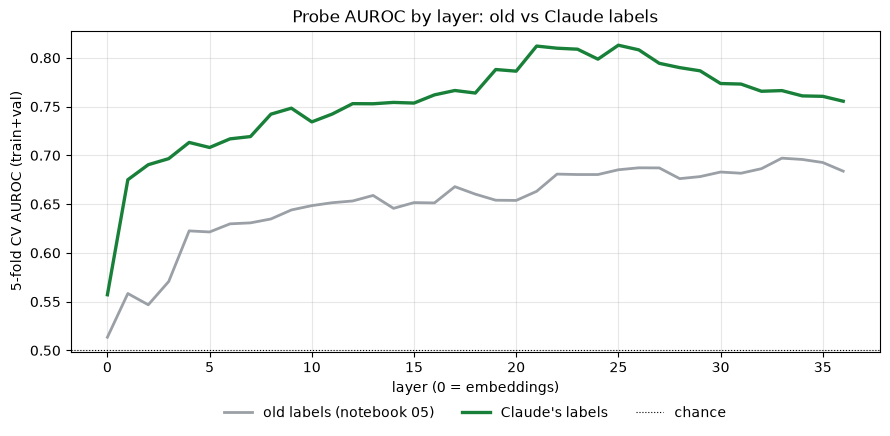

In [5]:
old = pd.read_csv(config.RESULTS_DIR / 'layer_sweep_Qwen2.5-3B-Instruct_answer_last_token.csv')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(old['layer_index'], old['cv_auroc'], color='#9aa0a6', lw=2, label='old labels (notebook 05)')
ax.plot(sweep['layer_index'], sweep['cv_auroc'], color='#188038', lw=2.4, label="Claude's labels")
ax.axhline(0.5, color='black', lw=0.8, ls=':', label='chance')
ax.set_xlabel('layer (0 = embeddings)'); ax.set_ylabel('5-fold CV AUROC (train+val)')
ax.set_title('Probe AUROC by layer: old vs Claude labels'); ax.grid(alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig.tight_layout(); fig.savefig(config.RESULTS_DIR / f'layer_sweep_{tag}.png', dpi=150); plt.show()

## C · Improvement ablation (notebook 06 candidates)

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from src.improve import best_over_C, C_GRID, layer_ensemble, auto_layer, average, stacked_with_uncertainty
from src.relabel import confident_only

avg = {rep: layer_average(getattr(d, rep), LATE) for rep in ('answer_last', 'answer_mean', 'question_last')}
feat = lambda X: (lambda i: X[i])
L16 = feat(d.answer_last[:, 16])

def lda(f):
    def fp(tr, te):
        m = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'))
        return m.fit(f(tr), d.y[tr]).predict_proba(f(te))[:, 1]
    return fp

def mass_mean(f):
    def fp(tr, te):
        s = StandardScaler().fit(f(tr)); X = s.transform(f(tr)); y = d.y[tr]
        w = X[y == 1].mean(0) - X[y == 0].mean(0)
        z = s.transform(f(te)) @ w - (X @ w).mean()          # centre on the training scores
        return 1 / (1 + np.exp(-z / (np.std(X @ w) + 1e-9)))   # squash so p > 0.5 means 'hallucination'
    return fp

high = lambda make: (lambda C: confident_only(d, conf, HIGH, make(C)))
ablation = [
    ('Baseline: layer 16, last token', lambda C: linear_probe(d, L16, C), C_GRID),
    ('Layer 16 + high-confidence labels only', high(lambda C: linear_probe(d, L16, C)), C_GRID),
    ('Best single layer (nested CV)', lambda C: auto_layer(d, 'answer_last', C), [1e-3]),
    ('One probe per layer 18-36, averaged', lambda C: layer_ensemble(d, 'answer_last', LATE, C), [1e-3]),
    ('Layer-averaged state 18-36', lambda C: linear_probe(d, feat(avg['answer_last']), C), C_GRID),
    ('Answer mean, layer-averaged 18-36', lambda C: linear_probe(d, feat(avg['answer_mean']), C), C_GRID),
    ('Question last token, layer-averaged 18-36', lambda C: linear_probe(d, feat(avg['question_last']), C), C_GRID),
    ('Last + mean + question, averaged', lambda C: average(*[linear_probe(d, feat(avg[r]), C) for r in avg]), C_GRID),
    ('Uncertainty features alone', lambda C: linear_probe(d, feat(d.uncertainty), C), [0.01, 0.1, 1.0]),
    ('Layer-averaged + uncertainty (stacked)', lambda C: stacked_with_uncertainty(d, linear_probe(d, feat(avg['answer_last']), C)), [1e-3]),
    ('Layer-averaged, PCA 64 + LR', lambda C: linear_probe(d, feat(avg['answer_last']), C, pca=64), [1e-3, 1e-2, 1e-1]),
    ('Layer-averaged, shrinkage LDA', lambda C: lda(feat(avg['answer_last'])), [None]),
    ('Layer-averaged, mass-mean probe', lambda C: mass_mean(feat(avg['answer_last'])), [None]),
    ('Layer-averaged 18-36 + high-confidence labels', high(lambda C: linear_probe(d, feat(avg['answer_last']), C)), C_GRID),
]
rows = []
for name, make, Cs in ablation:
    C = best_over_C(d, make, Cs, repeats=1)['C'] if len(Cs) > 1 else Cs[0]
    r = record('C', name, make(C))
    rows.append({'candidate': name, 'C': C, **{k: v for k, v in r.items()}})
ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(config.RESULTS_DIR / f'improvement_ablation_{tag}.csv', index=False)
ablation_df.drop(columns=['cv_auroc_std']).round(3)

,candidate,C,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_f1,test_auroc
0,"Baseline: layer 16, last token",0.001,0.750,0.711,0.787,0.823,0.680,0.663,0.586,0.726
1,Layer 16 + high-confidence labels only,0.010,0.754,0.707,0.720,0.801,0.693,0.667,0.582,0.714
2,Best single layer (nested CV),0.001,0.796,0.741,0.827,0.844,0.693,0.667,0.582,0.742
3,"One probe per layer 18-36, averaged",0.001,0.789,0.734,0.800,0.830,0.720,0.695,0.618,0.768
4,Layer-averaged state 18-36,0.001,0.771,0.716,0.747,0.820,0.707,0.684,0.607,0.735
5,"Answer mean, layer-averaged 18-36",0.001,0.753,0.676,0.733,0.771,0.653,0.628,0.536,0.718
6,"Question last token, layer-averaged 18-36",0.000,0.719,0.663,0.653,0.699,0.640,0.605,0.491,0.703
7,"Last + mean + question, averaged",0.001,0.767,0.689,0.747,0.788,0.680,0.650,0.556,0.727
8,Uncertainty features alone,1.000,0.624,0.610,0.613,0.639,0.560,0.552,0.476,0.580
9,Layer-averaged + uncertainty (stacked),0.001,0.770,0.705,0.707,0.804,0.693,0.674,0.596,0.732


## D · Model comparison (notebook 07 models + DualPositionNet)
Input: the layer-averaged state 18–36 (the layer-weighting nets see the 19 layers stacked; DualPositionNet sees last-token and mean-token stacks). Trained on all of Claude's labels. Each model's grid is picked by one round of CV, then the chosen setting is evaluated with the full protocol.

In [7]:
from src.model_compare import model_zoo, sk_model
from src.relabel import DualPositionNet
from src.improve import cv_auroc

X = {'avg': avg['answer_last'], 'stack': d.answer_last[:, LATE],
     'dual': np.stack([d.answer_last[:, LATE], d.answer_mean[:, LATE]], 1)}
zoo = model_zoo()
zoo['Neural net: DualPositionNet (new)'] = {'family': 'neural', 'input': 'dual', 'grid': {
    f'h={h}': (lambda h=h: DualPositionNet(hidden=h, dropout=0.5, epochs=150, lr=3e-4)) for h in (64, 128)}}

rows = []
for name, spec in zoo.items():
    f = (lambda k: (lambda i: X[k][i]))(spec['input'])
    grid = {label: cv_auroc(d, sk_model(d, f, make), repeats=1)['cv_auroc'] for label, make in spec['grid'].items()}
    setting = max(grid, key=grid.get)
    r = record('D', name, sk_model(d, f, spec['grid'][setting]))
    rows.append({'model': name, 'family': spec['family'], 'setting': setting, **r})
zoo_df = pd.DataFrame(rows).sort_values('cv_auroc', ascending=False)
zoo_df.to_csv(config.RESULTS_DIR / f'model_comparison_{tag}.csv', index=False)
zoo_df.drop(columns=['cv_auroc_std']).round(3)

,model,family,setting,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_f1,test_auroc
10,Neural net: learned layer weights + MLP,neural,"h=64,epochs=200",0.796,0.747,0.800,0.828,0.707,0.684,0.607,0.738
11,Neural net: DualPositionNet (new),neural,h=128,0.790,0.722,0.787,0.821,0.680,0.644,0.538,0.729
9,Neural net: learned layer weights + linear,neural,epochs=100,0.787,0.718,0.773,0.851,0.693,0.674,0.596,0.718
0,Logistic regression (baseline),linear,C=0.001,0.771,0.716,0.747,0.820,0.707,0.684,0.607,0.735
8,"Neural net: MLP, 1 hidden layer",neural,"h=64,epochs=150",0.768,0.707,0.720,0.796,0.667,0.620,0.490,0.698
2,Linear SVM,linear,C=0.0001,0.768,0.705,0.720,0.798,0.733,0.681,0.565,0.777
4,k-nearest neighbours,instance,k=15,0.763,0.704,0.760,0.790,0.720,0.689,0.604,0.786
3,RBF-kernel SVM,kernel,C=3.0,0.762,0.653,0.707,0.834,0.680,0.605,0.400,0.715
1,"Logistic regression, L1 (sparse)",linear,C=0.1,0.762,0.680,0.733,0.800,0.667,0.645,0.561,0.726
6,Random forest,trees,max_features=0.1,0.761,0.702,0.747,0.822,0.733,0.706,0.630,0.769


## Everything in one table

In [8]:
summary = pd.DataFrame(summary_rows).drop_duplicates('model').sort_values('cv_auroc', ascending=False)
summary.to_csv(config.RESULTS_DIR / f'all_models_{tag}.csv', index=False)
(config.RESULTS_DIR / f'all_models_{tag}.json').write_text(json.dumps({
    'labels': 'Claude (src/llm_judge.py)', 'agreement_with_old_labels': float((old_y == d.y).mean()),
    'protocol': 'CV: grouped 5-fold on train+val x3. Val: fit train, score val. Test: fit train+val, score test once. Accuracy at p > 0.5. Settings picked by CV AUROC.',
    'best_layer_by_cv': best_cv_layer, 'models': summary.to_dict(orient='records')}, indent=2, default=float))
cols = ['part', 'model', 'cv_auroc', 'cv_accuracy', 'val_accuracy', 'val_auroc', 'test_accuracy', 'test_balanced_accuracy', 'test_auroc']
summary[cols].round(3)

,part,model,cv_auroc,cv_accuracy,val_accuracy,val_auroc,test_accuracy,test_balanced_accuracy,test_auroc
25,D,Neural net: learned layer weights + MLP,0.796,0.747,0.800,0.828,0.707,0.684,0.738
3,C,Best single layer (nested CV),0.796,0.741,0.827,0.844,0.693,0.667,0.742
26,D,Neural net: DualPositionNet (new),0.790,0.722,0.787,0.821,0.680,0.644,0.729
4,C,"One probe per layer 18-36, averaged",0.789,0.734,0.800,0.830,0.720,0.695,0.768
24,D,Neural net: learned layer weights + linear,0.787,0.718,0.773,0.851,0.693,0.674,0.718
14,C,Layer-averaged 18-36 + high-confidence labels,0.784,0.725,0.827,0.824,0.693,0.667,0.772
5,C,Layer-averaged state 18-36,0.771,0.716,0.747,0.820,0.707,0.684,0.735
15,D,Logistic regression (baseline),0.771,0.716,0.747,0.820,0.707,0.684,0.735
10,C,Layer-averaged + uncertainty (stacked),0.770,0.705,0.707,0.804,0.693,0.674,0.732
23,D,"Neural net: MLP, 1 hidden layer",0.768,0.707,0.720,0.796,0.667,0.620,0.698


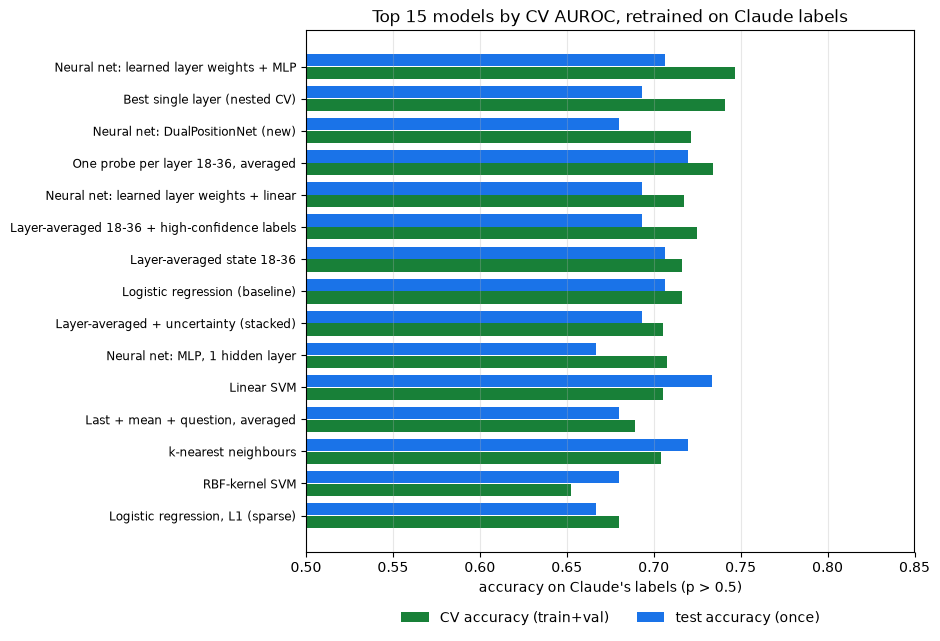

In [9]:
top = summary.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 6.5))
y = np.arange(len(top))
ax.barh(y - 0.2, top['cv_accuracy'], height=0.38, color='#188038', label='CV accuracy (train+val)')
ax.barh(y + 0.2, top['test_accuracy'], height=0.38, color='#1a73e8', label='test accuracy (once)')
ax.set_yticks(y); ax.set_yticklabels(top['model'], fontsize=8.5)
ax.set_xlim(0.5, 0.85); ax.set_xlabel("accuracy on Claude's labels (p > 0.5)")
ax.set_title('Top 15 models by CV AUROC, retrained on Claude labels'); ax.grid(axis='x', alpha=0.3)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
fig.tight_layout(); fig.savefig(config.RESULTS_DIR / f'all_models_{tag}.png', dpi=150); plt.show()